In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [3]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from model import NeuralNetwork


class CartPoleTrainer:
    def __init__(self, env_name="CartPole-v1", hidden_dim=256):
        torch.manual_seed(42)
        np.random.seed(42)
        self.gamma = 0.99  # Discount factor for future rewards

        self.env = gym.make(env_name)
        self.input_dim = self.env.observation_space.shape[0]
        self.output_dim = self.env.action_space.n
        self.hidden_dim = hidden_dim
        self.model = NeuralNetwork(self.input_dim, self.hidden_dim, self.output_dim)
        self.optimizer = optim.Adam(self.model.parameters(), lr=0.001)
        # self.optimizer = torch.optim.RMSprop(self.model.parameters(), lr=0.003)
        self.max_steps = 500 # Maximum number of steps per episode
        self.scores = []


    def train(self, episodes=1000):
        for episode in range(episodes):
            log_probs = []
            episode_rewards = []
            observation, _ = self.env.reset()

            for t in range(self.max_steps):  # Limit the maximum number of steps per episode
                action_logits = self.model(torch.tensor(observation, dtype=torch.float32))
                distribution = torch.distributions.Categorical(logits=action_logits)
                action = distribution.sample()
                log_probs.append(distribution.log_prob(action))

                observation, reward, terminated, truncated, _ = self.env.step(action.item())
                episode_rewards.append(reward)
                
                if terminated or truncated:
                    break

            self.scores.append(len(episode_rewards))

            returns = self.calc_returns(episode_rewards)
            returns = torch.FloatTensor(returns)
            # Normalize the returns to reduce variance in the policy gradient
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

            # Calculate the policy loss using the log probabilities and returns
            policy_loss = -torch.sum(torch.stack(log_probs) * returns)

            # Backpropagate the policy loss and update the model parameters
            self.optimizer.zero_grad()
            policy_loss.backward()
            self.optimizer.step()

            if episode % 50 == 0 and episode > 0:
                print(f'Episode {episode}, Average Score: {np.mean(self.scores[-50:-1]):.2f}')

    def calc_returns(self, episode_rewards):
        # calculate the return for the trajectory backwards using the discount factor
        returns = []
        cumulative_return = 0
        for reward in reversed(episode_rewards):
            cumulative_return = reward + self.gamma * cumulative_return
            returns.append(cumulative_return)
        returns.reverse()
        return returns

trainer = CartPoleTrainer()
trainer.train()

Episode 50, Average Score: 35.82
Episode 100, Average Score: 59.57
Episode 150, Average Score: 127.22
Episode 200, Average Score: 179.98
Episode 250, Average Score: 243.39
Episode 300, Average Score: 392.27
Episode 350, Average Score: 352.73
Episode 400, Average Score: 409.45
Episode 450, Average Score: 411.00
Episode 500, Average Score: 455.20
Episode 550, Average Score: 158.39
Episode 600, Average Score: 118.02
Episode 650, Average Score: 96.00
Episode 700, Average Score: 91.41
Episode 750, Average Score: 151.39
Episode 800, Average Score: 267.33
Episode 850, Average Score: 497.06
Episode 900, Average Score: 481.86
Episode 950, Average Score: 488.65


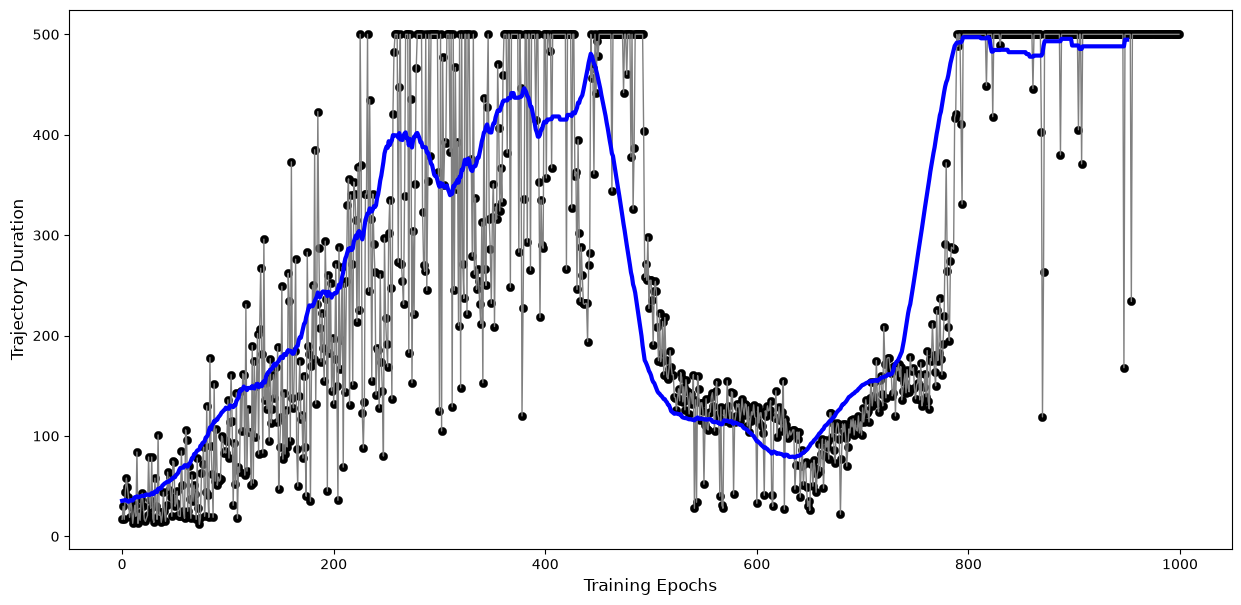

In [4]:
def running_mean(x, N=50):
    return np.convolve(x, np.ones(N)/N, mode='valid')


score = np.array(trainer.scores)
avg_score = running_mean(score)


def plot_score():
    plt.figure(figsize=(15, 7))
    plt.ylabel("Trajectory Duration", fontsize=12)
    plt.xlabel("Training Epochs", fontsize=12)
    plt.plot(score, color='gray', linewidth=1)
    plt.scatter(np.arange(score.shape[0]), score, color='k', linewidth=0.3)
    plt.plot(avg_score, color='blue', linewidth=3)


plot_score()

Reward: 3093.0


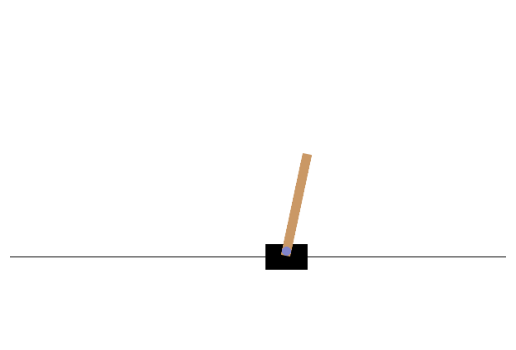

In [5]:
from IPython import display


def watch_agent(model):
    env = gym.make('CartPole-v1', render_mode="rgb_array")
    state = env.reset()[0]
    rewards = []
    img = plt.imshow(env.render())
    done = False
    while not done:
        pred = model(torch.from_numpy(state).float())
        action = torch.distributions.Categorical(logits=pred).sample().item()
        next_state, reward, done, _, _ = env.step(action)
        state = next_state

        img.set_data(env.render())
        plt.axis('off')
        display.display(plt.gcf())
        display.clear_output(wait=True)
        rewards.append(reward)

        if done:
            print("Reward:", sum([r for r in rewards]))
            break


watch_agent(trainer.model)